<a href="https://colab.research.google.com/github/lihueponcem/TFM---Gobernanza-calidad-y-modelado-dimensional-de-datos-abiertos-en-el-sector-p-blico/blob/main/Dataset_TFM_FISU.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**TRABAJO FINAL DE MÁSTER - DATASET FISU**

#**Capa Bronce**


##Configuración del entorno y conexión

In [ ]:
# Paso 1: Montar Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


##Ingesta y comprensión del dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime

# Ajusta la ruta/archivo
path = "/content/drive/MyDrive/Máster/TFM/Proyectos_FISU.csv"
df = pd.read_csv(path)

In [ ]:
df_fisu = df

In [ ]:
# Guardar en formato Parquet
df_fisu.to_parquet('/content/drive/MyDrive/Máster/TFM/fisu_bronce.parquet', index=False)

In [ ]:
df_fisu.shape

(1216, 13)

In [ ]:
df_fisu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1216 entries, 0 to 1215
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   ID RENABAP           1095 non-null   object
 1   Provincia            1216 non-null   object
 2   Municipio            1216 non-null   object
 3   Barrio               1095 non-null   object
 4   Localidad            1215 non-null   object
 5   Tipo de UE           1216 non-null   object
 6   Tipo de Proyecto     1216 non-null   object
 7   Nombre de Proyecto   1216 non-null   object
 8   Financiamiento       1216 non-null   object
 9   Estado               1216 non-null   object
 10  Monto Total          1216 non-null   object
 11  Acta de Inicio Real  1188 non-null   object
 12  % Avance físico      1188 non-null   object
dtypes: object(13)
memory usage: 123.6+ KB


El dataset del **Fondo de Integración Socio Urbana (FISU)** contiene 1.216 registros y 13 columnas relativas a los proyectos de integración socio-urbana financiados por el FISU en barrios populares de Argentina.

A continuación se presenta el desglose agrupado de las columnas según su tipo de información:

**1. Identificación y Localización**
**ID RENABAP:** Código identificador único asignado al barrio dentro del Registro Nacional de Barrios Populares. Puede contener un solo código (ej. 4637) o varios separados por barras si el proyecto abarca múltiples barrios (ej. 1561/625/1296).

**Provincia:** Nombre de la provincia o jurisdicción subnacional en la que se ejecuta la obra (ej. Buenos Aires, Chubut, Misiones).

**Municipio:** Nombre del municipio, partido o comuna donde se localiza la intervención (ej. La Plata, Lomas de Zamora).

**Barrio:** Denominación formal o popular del barrio alcanzado por el proyecto (ej. Barrio Padre Mugica).

**Localidad:** Localidad o ciudad específica dentro del municipio (ej. Gonnet, Mar del Plata).

---------------------

**2. Gestión y Tipología del Proyecto**
**Tipo de UE:** Sigla que representa al Tipo de Unidad Ejecutora, es decir, la entidad responsable de gestionar y realizar la obra. Los tipos registrados son:

- OSC: Organización de la Sociedad Civil.

- Municipio: Gobierno municipal.

- Provincia: Gobierno provincial.

- Coop. de servicios: Cooperativas de servicios públicos.

- SIN UE: Sin unidad ejecutora asignada o en proceso de asignación.

**Tipo de Proyecto:** Clasificación funcional de la obra según el programa de financiamiento:

- POT: Proyecto de Obras Tempranas (redes peatonales, espacios comunitarios, alumbrado, etc.).

- PEG: Proyecto Ejecutivo General o de infraestructura integral.

- LOTES: Proyectos de generación de suelo urbano con servicios.

- VIVIENDA: Construcción o mejoramiento habitacional.

- LOTES (Adq.): Adquisición de tierras para la creación de lotes.

**Nombre de Proyecto:** Descripción o título específico de la intervención edilicia o de infraestructura (ej. Equipamientos Comunitario y Espacio Recreativo, Centro Verde).

**Financiamiento:** Fuente de los recursos financieros aplicados al proyecto. En el 100% de los registros corresponde al valor FISU (Fondo de Integración Socio Urbana).

---------------------

**3. Estado, Ejecución y Montos**
**Estado:** Situación o fase administrativa/operativa actual del proyecto. Sus valores son:

- En ejecución: Obras activas en proceso de construcción.

- Terminado: Obras con finalización de trabajos.

- Pagado: Proyectos liquidados administrativamente.

**Monto Total:** Inversión financiera total aprobada y asignada al proyecto expresada en Pesos Argentinos (ARS).

**Acta de Inicio Real:** Fecha exacta en la que se firmó el acta de inicio formal de los trabajos en terreno (formato AAAA-MM-DD).

**% Avance físico:** Porcentaje estimado del progreso real alcanzado en la construcción de la obra en relación con la meta total prevista (de 0.00% a 100.00%).

In [ ]:
df_fisu.head(10)

,ID RENABAP,Provincia,Municipio,Barrio,Localidad,Tipo de UE,Tipo de Proyecto,Nombre de Proyecto,Financiamiento,Estado,Monto Total,Acta de Inicio Real,% Avance físico
0,4637,Ciudad Autónoma de Buenos Aires,Ciudad Autónoma de Buenos Aires,Barrio Padre Mugica,Ciudad Autónoma de Buenos Aires,OSC,POT,Equipamientos educativo - mejoramiento de jardin,FISU,En ejecución,"269,219,376.83",2024-04-15,40.25%
1,68,Buenos Aires,La Plata,Sin Nombre (esos locos bajitos),Gonnet,OSC,POT,Equipamientos Comunitario y Espacio Recreativo,FISU,En ejecución,"186,308,259.30",2023-12-01,25.97%
2,194,Buenos Aires,La Plata,Ruta del Sol,El Peligro,OSC,POT,Equipamiento Productivo,FISU,En ejecución,"181,540,041.99",2023-12-15,20.00%
3,72,Buenos Aires,Lomas de Zamora,Ocho de diciembre,Lomas de Zamora,OSC,POT,Centro Verde - etapa 02,FISU,En ejecución,"1,273,196,907.29",2023-09-22,64.36%
4,1561/625/1296/1232,Buenos Aires,General San Martín,La Carcova/Costa Esperanza/Veinticinco de Mayo...,NaN,OSC,POT,Obras de Red Peatonal y Equipamiento Urbano,FISU,En ejecución,"29,355,856.79",2023-09-29,100.00%
5,4249,Buenos Aires,General Pueyrredón,El Caribe,Mar del Plata,OSC,POT,Obras de Red peatonal y Equipamiento Urbano,FISU,En ejecución,"25,683,193.02",2023-10-27,89.81%
6,97,Buenos Aires,La Plata,"El Zanjón/""19 y 77""",Altos de San Lorenzo,OSC,POT,Obras de Equipamiento,FISU,En ejecución,"72,486,878.77",2023-09-02,100.00%
7,1976,Misiones,Oberá,San José,Oberá,OSC,POT,Obras de conexiones e instalaciones intra lote...,FISU,En ejecución,"318,171,139.66",2024-04-12,20.12%
8,3533/3538,Chubut,Trelew,Moreira 3 y Moreira 4,Trelew,OSC,POT,Obras de integración socio urbana,FISU,En ejecución,"1,042,823,231.85",2023-09-25,61.50%
9,1128,Buenos Aires,Pilar,Pinazo,La Lonja,OSC,POT,Obras de Conexiones e instalaciones intra lote...,FISU,En ejecución,"616,417,789.85",2023-10-30,30.57%


In [ ]:
df_fisu.tail(10)

,ID RENABAP,Provincia,Municipio,Barrio,Localidad,Tipo de UE,Tipo de Proyecto,Nombre de Proyecto,Financiamiento,Estado,Monto Total,Acta de Inicio Real,% Avance físico
1206,2643/2657,Río Negro,San Carlos De Bariloche,Barda Este/Vivero,San Carlos De Bariloche,OSC,POT,Conexiones intra-domiciliarias de agua,FISU,Terminado,"25,265,295.20",2021-05-17,100.00%
1207,1065,Buenos Aires,La Plata,B° 74 y 153 (Sin Nombre)pias,Los Hornos,OSC,POT,"""Obras de Intras eléctricas, Veredas y Mobilia...",FISU,Terminado,"31,121,611.21",2021-03-22,100.00%
1208,4384,Buenos Aires,General Pueyrredón,Autódromo,Mar Del Plata,OSC,POT,"""Obras de Conexiones domiciliarias e intra lot...",FISU,Terminado,"6,554,357.28",2021-09-01,100.00%
1209,4507,Tucumán,San Miguel De Tucumán,Ampliación Muñecas III,San Miguel De Tucumán,OSC,POT,Obras de Conexiones intradomiciliarias eléctri...,FISU,Terminado,"53,167,025.15",2021-12-19,100.00%
1210,601,Buenos Aires,San Miguel,Mitre,Santa María,Municipio,POT,"""Obras de Infraestructura urbana (Ampliación d...",FISU,Terminado,"47,175,085.07",2021-07-19,100.00%
1211,1468,Buenos Aires,San Isidro,Santa Ana,Rodeo De La Cruz,Municipio,POT,"""Obras de Infraestructura urbana (Desague cloa...",FISU,En ejecución,"160,233,105.02",2021-05-14,96.90%
1212,547,Buenos Aires,Berisso,Santa Teresita II,Berisso,Municipio,POT,Obras de integración socio urbanas”,FISU,En ejecución,"787,627,738.48",2023-01-10,60.19%
1213,3032,Santa Fe,Santa Fe,Playa Norte,Santa Fe,OSC,POT,Obra de Equipamiento comunitario,FISU,Terminado,"98,431,256.70",2022-04-16,100.00%
1214,3533/3538,Chubut,Trelew,Moreira 3/Moreira 4,Trelew,Municipio,PEG,Obras de Integración Socio Urbana,FISU,En ejecución,"2,675,548,897.31",2022-11-18,6.92%
1215,462,Buenos Aires,Escobar,Villa Bote,Escobar,OSC,POT,"""Construcción de un SUM - Villa Bote""",FISU,Terminado,"13,235,310.80",2021-05-18,100.00%


In [ ]:
df_fisu.Provincia.unique()

array(['Ciudad Autónoma de Buenos Aires', 'Buenos Aires', 'Misiones',
       'Chubut', 'Río Negro', 'Santa Fe', 'Corrientes', 'Jujuy',
       'Santiago del Estero', 'Córdoba', 'Tucumán', 'Entre Ríos', 'Salta',
       'Neuquén', 'Mendoza', 'Chaco', 'Formosa', 'San Juan', 'San Luis',
       'Tierra del Fuego', 'La Rioja', 'Catamarca', 'La Pampa'],
      dtype=object)

Como primer detalle en la inspección del dataset podemos observar que no figura información específica ni un detalle de obras del FISU ejecutadas en la provincia de Santa Cruz.

Las únicas referencias vinculadas a Santa Cruz corresponden al Plan de Desarrollo Humano Integral:
Asambleas de diagnóstico: Santa Cruz fue una de las provincias donde se realizaron encuentros y asambleas participativas para elaborar el diagnóstico del plan.

Propuesta de Centros de Salud: Dentro de las propuestas de infraestructura comunitaria, se estimó la proyección de 2 Centros de Salud en barrios populares de Santa Cruz (sobre un total proyectado de 499 en todo el país).

###Archivos nulos y duplicados

In [ ]:
df_fisu.duplicated().sum()

np.int64(0)

In [ ]:
df_fisu.isnull().sum()

,0
ID RENABAP,121
Provincia,0
Municipio,0
Barrio,121
Localidad,1
Tipo de UE,0
Tipo de Proyecto,0
Nombre de Proyecto,0
Financiamiento,0
Estado,0


In [ ]:
nulos_fisu = df_fisu.isnull().sum()
porcentaje_nulos = (nulos_fisu / len(df_fisu)) * 100

df_nulos_fisu = pd.DataFrame({'Nulos': nulos_fisu, 'Porcentaje (%)': porcentaje_nulos})
print("\n--- AUDITORÍA DE COMPLETITUD ---")
print(df_nulos_fisu[df_nulos_fisu['Nulos'] > 0].sort_values(by='Porcentaje (%)', ascending=False))


--- AUDITORÍA DE COMPLETITUD ---
                     Nulos  Porcentaje (%)
ID RENABAP             121        9.950658
Barrio                 121        9.950658
Acta de Inicio Real     28        2.302632
% Avance físico         28        2.302632
Localidad                1        0.082237


/tmp/ipykernel_704/1215716503.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=df_nulos_filtrado.index, y='Porcentaje (%)', data=df_nulos_filtrado, palette='viridis')


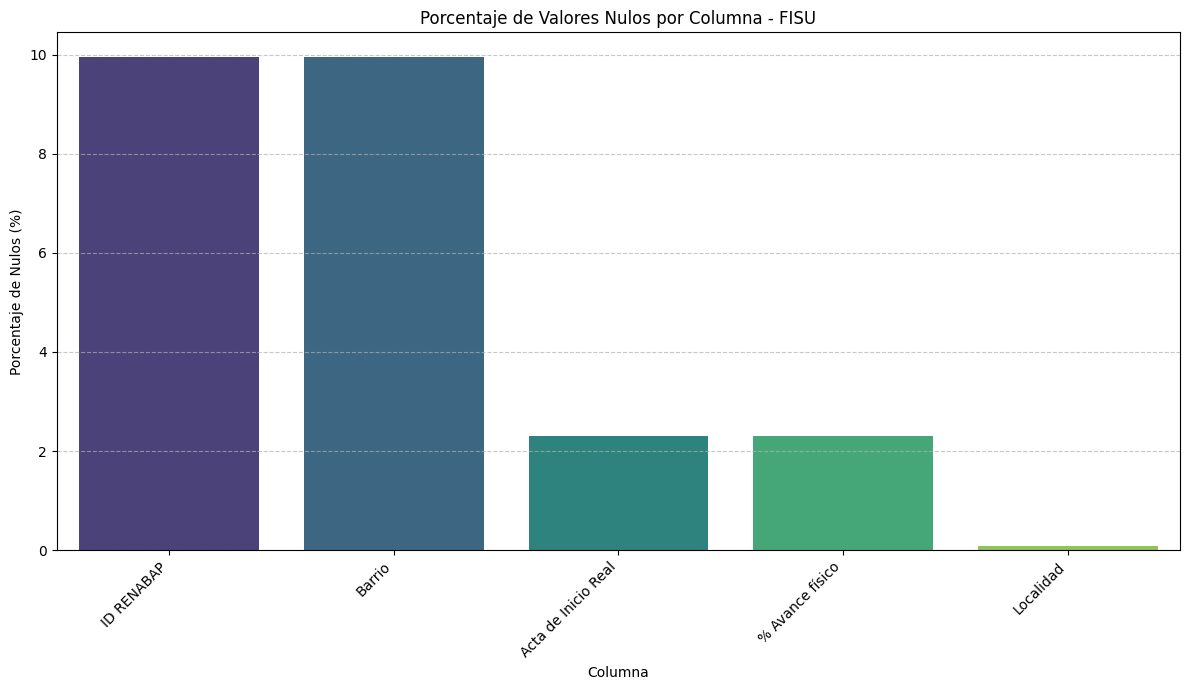

In [ ]:
plt.figure(figsize=(12, 7))
df_nulos_filtrado = df_nulos_fisu[df_nulos_fisu['Porcentaje (%)'] > 0].sort_values(by='Porcentaje (%)', ascending=False)

sns.barplot(x=df_nulos_filtrado.index, y='Porcentaje (%)', data=df_nulos_filtrado, palette='viridis')

plt.title('Porcentaje de Valores Nulos por Columna - FISU')
plt.xlabel('Columna')
plt.ylabel('Porcentaje de Nulos (%)')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#### Nulos de la columna 'ID RENABAP'

Para entender mejor los valores nulos en la columna 'ID RENABAP', primero vamos a observar cómo se representan los valores no nulos, especialmente aquellos que contienen múltiples IDs, y luego examinaremos las entradas que han sido identificadas como nulas.

In [ ]:
print('Ejemplos de IDs RENABAP con múltiples valores (no nulos):')
display(df_fisu[df_fisu['ID RENABAP'].astype(str).str.contains('/', na=False)].head(10)[['ID RENABAP']])

print('\nEjemplos de filas donde ID RENABAP es nulo:')
display(df_fisu[df_fisu['ID RENABAP'].isnull()].head(10)[['ID RENABAP', 'Barrio', 'Provincia', 'Municipio']])

Ejemplos de IDs RENABAP con múltiples valores (no nulos):


,ID RENABAP
4,1561/625/1296/1232
8,3533/3538
10,4509 / 4327
11,3748/4466/3745/3730/3753/3728/4932/4931/4930/4...
12,397/1174
17,5241/5242
44,4283/585/608
65,3525/4355
73,6012 / 6011
80,3535/3536



Ejemplos de filas donde ID RENABAP es nulo:


,ID RENABAP,Barrio,Provincia,Municipio
148,NaN,NaN,Buenos Aires,General Pueyrredón
152,NaN,NaN,Buenos Aires,Olavarría
154,NaN,NaN,Buenos Aires,Florencio Varela
162,NaN,NaN,Buenos Aires,Tandil
163,NaN,NaN,Mendoza,Las Heras
164,NaN,NaN,Buenos Aires,General Pueyrredón
174,NaN,NaN,San Juan,Ullum
175,NaN,NaN,Buenos Aires,General Pueyrredón
176,NaN,NaN,Buenos Aires,Mercedes
177,NaN,NaN,Córdoba,Santa María


#### Nulos en 'Acta de Inicio Real' y '% Avance físico'


In [ ]:
nulos_acta_avance = df_fisu[df_fisu['Acta de Inicio Real'].isnull() | df_fisu['% Avance físico'].isnull()]
display(nulos_acta_avance[['ID RENABAP', 'Barrio', 'Provincia', 'Acta de Inicio Real', '% Avance físico']])

,ID RENABAP,Barrio,Provincia,Acta de Inicio Real,% Avance físico
174,NaN,NaN,San Juan,NaN,NaN
178,NaN,NaN,Buenos Aires,NaN,NaN
184,NaN,NaN,Córdoba,NaN,NaN
189,NaN,NaN,Entre Ríos,NaN,NaN
207,NaN,NaN,Buenos Aires,NaN,NaN
208,NaN,NaN,Entre Ríos,NaN,NaN
213,NaN,NaN,Santa Fe,NaN,NaN
238,NaN,NaN,Buenos Aires,NaN,NaN
261,NaN,NaN,Formosa,NaN,NaN
267,NaN,NaN,Córdoba,NaN,NaN


#### Nulos en la columna 'Localidad'

In [ ]:
nulos_localidad = df_fisu[df_fisu['Localidad'].isnull()]
display(nulos_localidad[['ID RENABAP', 'Barrio', 'Provincia', 'Municipio', 'Localidad']])

,ID RENABAP,Barrio,Provincia,Municipio,Localidad
4,1561/625/1296/1232,La Carcova/Costa Esperanza/Veinticinco de Mayo...,Buenos Aires,General San Martín,NaN


In [ ]:
# Agregar metadatos de auditoría/ingesta
df_fisu['_fecha_ingesta'] = datetime.now()
df_fisu['_archivo_origen'] = 'Proyectos_FISU.csv'

# Guardar en formato Parquet
df_fisu.to_parquet('/content/drive/MyDrive/Máster/TFM/fisu_bronce.parquet', index=False)
print("Capa Bronce completada. Registros:", len(df_fisu))

Capa Bronce completada. Registros: 1216


#**Capa Plata**


###1) Proteger el dato original

In [ ]:
# Creación de una copia explícita desde la capa bronce
df_fisu_plata = df_fisu.copy()

###2) Estandarización de Nombres de Columnas

In [ ]:
# Renombrar 'ID RENABAP' a 'id_renabaP'
df_fisu_plata = df_fisu_plata.rename(columns={'ID RENABAP': 'id_renabap'})

In [ ]:
# Estandarizar nombres de columnas a snake_case
df_fisu_plata.columns = (
    df_fisu_plata.columns.str.strip()
    .str.lower()
    .str.replace(' ', '_')
    .str.replace('%', 'pct')
    .str.replace('á', 'a')
    .str.replace('é', 'e')
    .str.replace('í', 'i')
    .str.replace('ó', 'o')
    .str.replace('ú', 'u')
)

###3) Normalizar la Geografía y Cadenas Categóricas (Mayúsculas y sin tildes)

In [ ]:
cols_geograficas_fisu = ['provincia', 'municipio', 'localidad']

In [ ]:
for col in cols_geograficas_fisu:
  if col in df_fisu_plata.columns:
    df_fisu_plata[col] = (
        df_fisu_plata[col]
        .astype(str)
        .str.upper()
        .str.strip()
        .str.normalize('NFKD')
        .str.encode('ascii', errors='ignore')
        .str.decode('utf-8')
    )
print("Textos geográficos normalizados (Mayúsculas y sin tildes).")

Textos geográficos normalizados (Mayúsculas y sin tildes).


###4) Tratamiento de Columnas Multivaluadas y Distribución de Montos
La columna id_renabap contiene múltiples códigos separados por barras en los casos donde un proyecto abarca varios barrios, como "1561/625/1296/1232". Para mantener la Primera Forma Normal (1NF) y evitar errores de granularidad, se debe aplicar un explode() dividiendo estos valores, o bien diseñar una tabla puente (bridge table) para estructurar en un esquema de estrella.   

In [ ]:
# 1. Limpiar y convertir 'monto_total' a tipo numérico (float) antes de prorratear
df_fisu_plata['monto_total'] = (
    df_fisu_plata['monto_total']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df_fisu_plata['monto_total'] = pd.to_numeric(
    df_fisu_plata['monto_total'], errors='coerce'
)

# 2. Separar los IDs compuestos por '/' en listas
df_fisu_plata['id_renabap'] = (
    df_fisu_plata['id_renabap'].astype(str).str.split('/')
)

# 3. Contar cuántos barrios abarca cada proyecto
df_fisu_plata['cant_barrios'] = df_fisu_plata['id_renabap'].apply(len)

# 4. Distribuir el monto total dividiendo equitativamente entre los barrios impactados
df_fisu_plata['monto_total'] = (
    df_fisu_plata['monto_total'] / df_fisu_plata['cant_barrios']
)

# 5. Desanidar (explode) la columna 'id_renabap'
df_fisu_plata = df_fisu_plata.explode('id_renabap')

# 6. Limpiar espacios remanentes y hacer casting de id_renabap a entero (Int64)
df_fisu_plata['id_renabap'] = (
    df_fisu_plata['id_renabap'].astype(str).str.strip()
)
df_fisu_plata['id_renabap'] = pd.to_numeric(
    df_fisu_plata['id_renabap'], errors='coerce'
).astype('Int64')

###5) Transformación de Tipos de Datos (Casting)

Actualmente, las 13 columnas del dataset se reconocen como tipo object (cadenas de texto o "strings"). Es indispensable transformar estas variables para permitir agregaciones matemáticas y análisis temporales:  

id_renabap: Es necesario pasar la clave primaria a numérico

monto_total: Presenta valores con separadores de miles y decimales como "269,219,376.83". Se deben eliminar las comas y convertir la serie a float.  

pct_avance_físico: Los registros incluyen el carácter "%", por ejemplo, "40.25%". Es necesario remover el símbolo y convertir los valores a tipo numérico.  

acta_de_inicio_real: Los valores como "2024-04-15" deben transformarse explícitamente a tipo datetime mediante Pandas para habilitar el modelado cronológico.   

In [ ]:
df_fisu_plata['id_renabap'] = pd.to_numeric(
    df_fisu_plata['id_renabap'], errors='coerce'
).astype('Int64')

In [ ]:
# 1. Monto Total: eliminar comas de formato y convertir a numérico flotante
df_fisu_plata['monto_total'] = (
    df_fisu_plata['monto_total']
    .astype(str)
    .str.replace(',', '', regex=False)
    .str.strip()
)
df_fisu_plata['monto_total'] = pd.to_numeric(df_fisu_plata['monto_total'], errors='coerce')

# 2. % Avance físico: quitar el símbolo % y convertir a flotante
df_fisu_plata['pct_avance_fisico'] = (
    df_fisu_plata['pct_avance_fisico']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.strip()
)
df_fisu_plata['pct_avance_fisico'] = pd.to_numeric(df_fisu_plata['pct_avance_fisico'], errors='coerce')

# 3. Acta de Inicio Real: convertir a formato de fecha ISO
df_fisu_plata['acta_de_inicio_real'] = pd.to_datetime(
    df_fisu_plata['acta_de_inicio_real'],
    format='%Y-%m-%d',
    errors='coerce'
)

###6) Estrategia de Nulos e Imputación
La auditoría de completitud detectó registros faltantes que requieren reglas de negocio claras para su monitoreo de calidad:   id_renabap y Barrio: Presentan 121 valores nulos (casi el 10% de la muestra). Se debe definir si se rellenan con un valor predeterminado (ej. "Sin Asignar") o si se cruzan con otra fuente de datos.   Acta de Inicio Real y % Avance físico: Tienen 28 valores nulos. Podría requerirse una imputación de "0" en el avance si la obra no ha comenzado, o revisar la relación de estas filas con la columna Estado.   

In [ ]:
# 1. Si no hay avance físico registrado, imputar 0.0
df_fisu_plata['pct_avance_fisico'] = df_fisu_plata[
    'pct_avance_fisico'
].fillna(0.0)

# 2. Imputar texto predeterminado en campos categóricos sin registro
df_fisu_plata['barrio'] = df_fisu_plata['barrio'].fillna('Sin Asignar')

### 7) Observabilidad, Eliminación de Duplicados Exactos y Guardado

In [ ]:
df_fisu_plata = df_fisu_plata.drop_duplicates().reset_index(drop=True)

In [ ]:
# Guardar en Parquet
df_fisu_plata.to_parquet(
    '/content/drive/MyDrive/Máster/TFM/fisu_plata.parquet', index=False
)
print(
    "Capa Plata FISU completada. Registros finales:", len(df_fisu_plata)
)

Capa Plata FISU completada. Registros finales: 1476


#**Capa Oro**


Paso 1: Configuración inicial y carga de la Capa Plata

In [ ]:
ruta_fisu_plata = '/content/drive/MyDrive/Máster/TFM/fisu_plata.parquet'
df_fisu_plata = pd.read_parquet(ruta_fisu_plata)

df_fisu_oro = df_fisu_plata.copy()

Paso 2: Gobierno del dato: Clave foránea (id renabap): rellenar con 99999 los proyectos que no tienen un ID asignado antes de cualquier otra transformación. Esto asegura el cruce con el "Registro Desconocido" en ReNaBaP.

In [ ]:
df_fisu_oro['id_renabap'] = df_fisu_oro['id_renabap'].fillna(99999).astype('Int64')

Paso 3: Enriquecimiento Temporal y Relglas de Negocio: Creación de Banderas Temporales (Objetivo 4) Para analizar las variaciones en el ritmo de inicio de obras antes y después del 10 de diciembre de 2023, crearemos variables categóricas que facilitarán los filtros en Power BI. Además, las reglas de negocio serviran para medir el impacto real de las obras, es útil pre-calcular el estado de ejecución basándose en la variable % Avance físico

In [ ]:
# A. Desglose de fechas (Ideal para filtros rápidos en Power BI, aunque tengas tabla calendario)
if 'acta_de_inicio_real' in df_fisu_oro.columns:
    df_fisu_oro['anio_inicio'] = df_fisu_oro['acta_de_inicio_real'].dt.year.astype('Int64')
    df_fisu_oro['trimestre_inicio'] = df_fisu_oro['acta_de_inicio_real'].dt.quarter.astype('Int64')

# B. Creación de Período de de Gobierno"
def definir_periodo_gobierno(fecha):
  if pd.isna(fecha):
    return 'Sin Fecha Registrada'
  elif fecha < pd.Timestamp('2019-12-10'):
    return 'Mauricio Macri (2015-2019)'
  elif fecha < pd.Timestamp('2023-12-10'):
    return 'Alberto Fernández (2019-2023)'
  else:
    return 'Javier Milei (2023-Presente)'

# Generamos o sobreescribimos la columna en el DataFrame de Oro
if 'acta_de_inicio_real' in df_fisu_oro.columns:
  df_fisu_oro['periodo_gobierno'] = df_fisu_oro['acta_de_inicio_real'].apply(
      definir_periodo_gobierno
  )

# C. Estado de Ejecución Simplificado (Buscando siempre el 100%)
def asignar_estado(pct):
    if pd.isna(pct) or pct <= 0:
        return 'Sin Iniciar'
    elif pct >= 100:
        return 'Finalizada'
    else:
        return 'En Ejecución'

if 'pct_avance_fisico' in df_fisu_oro.columns:
    df_fisu_oro['estado_ejecucion'] = df_fisu_oro['pct_avance_fisico'].apply(asignar_estado)

# D. Bandera de Calidad: Alerta por montos inválidos (útil para auditoría)
if 'monto_total' in df_fisu_oro.columns:
    df_fisu_oro['alerta_monto'] = (df_fisu_oro['monto_total'].isna()) | (df_fisu_oro['monto_total'] <= 0)

Paso 4: Selección de Columnas para la Tabla de Hechos: Estructuración de la Tabla de Hechos (fact_fisu) En un modelo dimensional (esquema de estrella), la tabla de hechos solo debe contener claves foráneas (Foreign Keys) para relacionarse con las dimensiones y las métricas numéricas. Eliminaremos columnas descriptivas redundantes que ya viven en la dimensión ReNaBaP (como Provincia, Municipio, Localidad o Barrio) para evitar inconsistencias y reducir el tamaño del dataset.

In [ ]:
columnas_hechos = [
    'id_renabap',
    'nombre_proyecto',
    'tipo_proyecto',
    'periodo_gobierno',
    'acta_de_inicio_real',
    'anio_inicio',
    'trimestre_inicio',
    'monto_total',
    'pct_avance_fisico',
    'estado_ejecucion',
    'alerta_monto'
]

# Filtrar asegurando que solo se seleccionen columnas que realmente existan
cols_presentes = [col for col in columnas_hechos if col in df_fisu_oro.columns]
df_fisu_oro = df_fisu_oro[cols_presentes]

Paso 5: Presentación semántica: Nombres para Power Bi

In [ ]:
diccionario_nombres_fisu = {
    'id_renabap': 'ID ReNaBaP',
    'nombre_proyecto': 'Nombre del Proyecto',
    'tipo_proyecto': 'Tipo de Proyecto',
    'periodo_gobierno': 'Periodo de Gobierno',
    'acta_de_inicio_real': 'Fecha de Inicio',
    'anio_inicio': 'Año de Inicio',
    'trimestre_inicio': 'Trimestre de Inicio',
    'monto_total': 'Monto Total',
    'pct_avance_fisico': '% Avance Físico',
    'estado_ejecucion': 'Estado de Ejecución',
    'alerta_monto': 'Alerta Monto Inválido'
}

df_fisu_oro = df_fisu_oro.rename(columns=diccionario_nombres_fisu)

Paso 6: Exportacióna Capa Oro

In [ ]:
ruta_salida_fisu = '/content/drive/MyDrive/Máster/TFM/fact_fisu_oro.parquet'
df_fisu_oro.to_parquet(ruta_salida_fisu, index=False)

Paso 7: Snapshot de Observabilidad del Dato
Generamos un registro de control de calidad para monitorear la salud de los datos en tiempo de ejecución.

In [ ]:
# Cálculos de calidad
total_proyectos = len(df_fisu_oro)

# Usamos los nombres ya transformados en el paso 5
proyectos_sin_id = df_fisu_oro[df_fisu_oro['ID ReNaBaP'] == 99999].shape[0]

proyectos_sin_iniciar = 0
if 'Estado de Ejecución' in df_fisu_oro.columns:
    proyectos_sin_iniciar = df_fisu_oro[df_fisu_oro['Estado de Ejecución'] == 'Sin Iniciar'].shape[0]

montos_invalidos = 0
if 'Alerta Monto Inválido' in df_fisu_oro.columns:
    montos_invalidos = df_fisu_oro[df_fisu_oro['Alerta Monto Inválido'] == True].shape[0]

# Crear el registro del log
log_observabilidad_fisu = pd.DataFrame({
    'Fecha_Ejecucion': [datetime.now().strftime('%Y-%m-%d %H:%M:%S')],
    'Tabla': ['fact_fisu'],
    'Total_Proyectos': [total_proyectos],
    'Proyectos_ID_Desconocido': [proyectos_sin_id],
    'Proyectos_Sin_Iniciar': [proyectos_sin_iniciar],
    'Alertas_Monto_Invalido': [montos_invalidos],
    'Frescura_Dato': ['Actualizado']
})

print("=========================================================")
print("✅ CAPA ORO FISU (TABLA DE HECHOS) GENERADA CON ÉXITO")
print(f"-> Total de proyectos procesados: {total_proyectos}")
print(f"-> Proyectos huérfanos/sin ID asignado (99999): {proyectos_sin_id}")
print("=========================================================")
print("\nLOG DE OBSERVABILIDAD FISU:")
display(log_observabilidad_fisu)

# Barrios únicos con al menos un proyecto
barrios_con_proyectos = df_fisu_oro[df_fisu_oro['ID ReNaBaP'] != 99999]['ID ReNaBaP'].nunique()

print(f"Cantidad de barrios únicos con al menos un proyecto (excluyendo ID Desconocido): {barrios_con_proyectos}")

# Barrios con más de un proyecto
proyectos_por_barrio = df_fisu_oro[df_fisu_oro['ID ReNaBaP'] != 99999].groupby('ID ReNaBaP').size()
barrios_con_multiples_proyectos = (proyectos_por_barrio > 1).sum()

print(f"Cantidad de barrios que tienen más de un proyecto: {barrios_con_multiples_proyectos}")

# Guardar y apendizar el log
ruta_log_fisu = '/content/drive/MyDrive/Máster/TFM/log_observabilidad_fisu.csv'

if not os.path.exists(ruta_log_fisu):
    log_observabilidad_fisu.to_csv(ruta_log_fisu, index=False)
else:
    log_observabilidad_fisu.to_csv(ruta_log_fisu, mode='a', header=False, index=False)

✅ CAPA ORO FISU (TABLA DE HECHOS) GENERADA CON ÉXITO
-> Total de proyectos procesados: 1476
-> Proyectos huérfanos/sin ID asignado (99999): 125

LOG DE OBSERVABILIDAD FISU:


,Fecha_Ejecucion,Tabla,Total_Proyectos,Proyectos_ID_Desconocido,Proyectos_Sin_Iniciar,Alertas_Monto_Invalido,Frescura_Dato
0,2026-10-15 16:15:06,fact_fisu,1476,125,30,3,Actualizado


Cantidad de barrios únicos con al menos un proyecto (excluyendo ID Desconocido): 1054
Cantidad de barrios que tienen más de un proyecto: 225
